# Validate mobility with a distance law and flow models

**Question.** From raw GPS tracks, how do I check that the movement of my sample follows a distance law, with an honest uncertainty, and that a gravity or radiation model reproduces the flows between places?

**You will get** the full cycle on one dataset: cleaned tracks, stops, the distribution of trip lengths fitted with confidence intervals and compared with alternative forms, flows between places, a gravity fit with its distance-decay parameter and confidence interval, and a held-out comparison of the gravity and the radiation model.

**Prerequisites.** [Clean noisy GPS data and find stops](clean-and-detect-stops.md) and [How the fits work](fitting-methods.md).

**Data.** [GeoLife](https://www.microsoft.com/en-us/download/details.aspx?id=52367), GPS tracks of Beijing residents collected by Microsoft Research Asia. `fastmob.data.load_geolife` reads the first 60 trips of users 000 to 029 straight from the public archive (about 2.7 million position fixes; the first run downloads several tens of megabytes and takes a few minutes). Check the dataset page for its terms of use before redistributing the data. If the download fails the notebook stops; it never substitutes other data.

In [1]:
%pip install -q 'fastmob>=0.3.4' pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## Load and clean

We keep fixes inside the urban area of Beijing and drop the ones that would need an impossible speed (above 200 km/h, as in the cleaning notebook).

In [2]:
import fastmob
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from fastmob.core import FlowDataFrame, Locations
from fastmob.data import load_geolife
from fastmob.measures.evaluation import compare_flow_models
from fastmob.measures.fitting import (
    compare_distance_distributions,
    fit_distance_distribution,
    likelihood_ratio_test,
)
from fastmob.models import Gravity, Radiation

users = [f"{i:03d}" for i in range(30)]
fixes = load_geolife(users=users, max_trips_per_user=60).to_pandas()
clean = fastmob.filter(fixes, max_speed_kmh=200)
clean = clean[clean["lat"].between(39.6, 40.3) & clean["lng"].between(116.0, 116.8)]
print(f"{len(fixes):,} fixes, {len(clean):,} kept, {clean['uid'].nunique()} users")

2,728,148 fixes, 2,012,465 kept, 30 users


## From fixes to trips

At one fix every few seconds, consecutive fixes are not trips. A trip goes from one stop to the next, so we find where each person stayed at least 20 minutes within 200 m (`stay_locations`) and treat each pair of consecutive stops of a person as one trip.

In [3]:
stays = fastmob.stay_locations(clean, minutes_for_a_stop=20, spatial_radius_km=0.2)
print(f"{len(stays):,} stops by {stays['uid'].nunique()} people, {len(stays) - stays['uid'].nunique():,} trips between consecutive stops")

3,367 stops by 30 people, 3,337 trips between consecutive stops


## Step 1: the distribution of trip lengths

`jump_lengths` on the stops gives the straight-line length of each trip. We fit the five families by maximum likelihood from 0.2 km upwards (the radius of a stop: two stops closer than that are the same place) up to the largest trip that is possible in the study area, the diagonal of the box we kept. The upper limit matters: when it is left out, the largest observed trip becomes the end of the distribution and a cutoff can hide behind it. A family with a parameter on the edge of its search range that is not a legitimate limit is a degenerate fit: it is listed last, with no Akaike weight.

In [4]:
trip_lengths = fastmob.jump_lengths(stays)
lengths = np.concatenate(trip_lengths["jump_lengths"].to_list())
owner = np.repeat(trip_lengths["uid"].to_numpy(), trip_lengths["jump_lengths"].map(len).to_numpy())

# minutes between leaving one stop and arriving at the next, in the same order as the trip lengths
ordered = stays.sort_values(["uid", "datetime"])
minutes = (ordered.groupby("uid")["datetime"].shift(-1) - ordered["leaving_datetime"]).dt.total_seconds() / 60
per_user = {u: g.to_numpy() for u, g in minutes.dropna().groupby(ordered.loc[minutes.dropna().index, "uid"])}
gap = np.concatenate([per_user.get(u, np.empty(0)) for u in trip_lengths["uid"]])

usable = np.isfinite(lengths) & (lengths > 0)
lengths, owner, gap = lengths[usable], owner[usable], gap[usable]
print(f"{len(lengths):,} trips, median {np.median(lengths):.1f} km, longest {lengths.max():.0f} km")
print(f"{(gap < 1).mean():.1%} of the trips start less than a minute after the previous stop ended")

3,335 trips, median 1.3 km, longest 62 km
13.5% of the trips start less than a minute after the previous stop ended


The 3,335 trips have a median of 1.3 km and the longest is 62 km. Of them, 13.5% (451) start less than a minute after the previous stop ended: the person reappears somewhere else, which is a recording gap and not travel. They stay in the data here, and the section on the range below checks that removing them changes little.

In [5]:
# the largest possible trip in the study area: the diagonal of the box that we kept (km)
lat0, lat1, lng0, lng1 = np.radians([39.6, 40.3, 116.0, 116.8])
h = np.sin((lat1 - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat1) * np.sin((lng1 - lng0) / 2) ** 2
xmax = 2 * 6371.0088 * np.arcsin(np.sqrt(h))
print(f"largest possible trip in the area: {xmax:.1f} km")
compare_distance_distributions(lengths, xmin=0.2, xmax=xmax).to_pandas().round(2)

largest possible trip in the area: 103.5 km


,family,n_parameters,log_likelihood,aic,bic,delta_aic,akaike_weight,ks_statistic,gof_p_value,at_bound,degenerate
0,truncated_powerlaw,3,-14126.45,28258.89,28276.67,0.00,1.0,0.05,None,,False
1,lognormal,2,-14146.16,28296.31,28308.16,37.42,0.0,0.05,None,,False
2,shifted_powerlaw,2,-14163.14,28330.27,28342.12,71.38,0.0,0.06,None,,False
3,powerlaw,1,-14468.58,28939.17,28945.09,680.27,0.0,0.12,None,,False
4,exponential,1,-14606.42,29214.83,29220.76,955.94,0.0,0.23,None,,False


With the upper limit set to the 103.5 km diagonal of the area, the truncated power law ranks first with an Akaike weight of 1.0. The log-normal is 37 AIC units behind, the shifted power law (no cutoff) 71, and the plain power law and the exponential far behind (680 and 956). No family is degenerate, so the ranking can be read. The gaps are large even though the 2,765 trips of 30 people are not independent: a cutoff is needed. Leaving the upper limit at the longest observed trip (62 km) would have shrunk the gap to the log-normal to 7 units, because the sample maximum then acts as the end of the distribution.

In [6]:
fit = fit_distance_distribution(lengths, "truncated_powerlaw", xmin=0.2, xmax=xmax, n_bootstrap=100, groups=owner)
shifted = fit_distance_distribution(lengths, "shifted_powerlaw", xmin=0.2, xmax=xmax, n_bootstrap=0)
truncated = fit_distance_distribution(lengths, "truncated_powerlaw", xmin=0.2, xmax=xmax, n_bootstrap=0)
test = likelihood_ratio_test(shifted, truncated, n_bootstrap=100)
print(f"{fit.n:,} trips between {fit.xmin:.1f} and {fit.xmax:.0f} km; KS distance {fit.ks_statistic:.3f}; at the edge: {fit.at_bound or 'none'}")
print(f"cutoff against no cutoff: statistic {test.statistic:.1f}, bootstrap p = {test.p_value:.3f} (asymptotic {test.asymptotic_p_value:.1g})")
print(truncated.profile("kappa"))
fit.summary().to_pandas().round(3)

2,765 trips between 0.2 and 103 km; KS distance 0.053; at the edge: none
cutoff against no cutoff: statistic 73.4, bootstrap p = 0.010 (asymptotic 5e-18)


kappa in [17.78, 27.9] (95%), estimate 21.72


,parameter,estimate,std_error,ci_low,ci_high,at_bound
0,r0,0.568,0.390,0.002,1.479,False
1,beta,1.153,0.275,0.654,1.701,False
2,kappa,21.722,10.125,11.454,44.585,False


The cutoff is `kappa` = 21.7 km, with an exponent `beta` = 1.15 and a shift `r0` = 0.57 km; no parameter is on the edge of its range. The likelihood-ratio test of a cutoff against none has a statistic of 73.4. The asymptotic p-value (5e-18) is not to be trusted at this size; the parametric bootstrap p-value is 0.010, the smallest value that 100 replicates can give, since none of them reached the observed statistic. The profile likelihood interval of `kappa`, which treats the trips as independent, is 17.8 to 27.9 km. The interval that resamples the 30 people is wider, 11.5 to 44.6 km, and no resample hit the search bound; report that one. The intervals of `beta` (0.65 to 1.70) and `r0` (0.002 to 1.5 km) are wide. The KS distance of 0.053 is the largest gap between the fitted and the empirical cumulative distribution.

In [7]:
rows = []
for xmin in (0.2, 0.5, 1.0, 2.0):
    f = fit_distance_distribution(lengths, "truncated_powerlaw", xmin=xmin, xmax=xmax, n_bootstrap=0)
    lr = likelihood_ratio_test(
        fit_distance_distribution(lengths, "shifted_powerlaw", xmin=xmin, xmax=xmax, n_bootstrap=0), f
    )
    rows.append({"xmin (km)": xmin, "trips": f.n, "beta": f.parameters["beta"], "kappa (km)": f.parameters["kappa"],
                 "cutoff test statistic": lr.statistic, "p (asymptotic)": f"{lr.p_value:.0e}", "at the edge": ", ".join(f.at_bound)})
far = gap >= 1
without = fit_distance_distribution(lengths[far], "truncated_powerlaw", xmin=0.2, xmax=xmax, n_bootstrap=0)
print(f"without the {(~far).sum()} trips that start within a minute of the previous stop: beta = {without.parameters['beta']:.2f}, kappa = {without.parameters['kappa']:.1f} km")
pd.DataFrame(rows).round(3)

without the 451 trips that start within a minute of the previous stop: beta = 1.28, kappa = 23.9 km


,xmin (km),trips,beta,kappa (km),cutoff test statistic,p (asymptotic),at the edge
0,0.2,2765,1.153,21.722,73.377,5e-18,
1,0.5,2413,1.031,19.865,82.957,4e-20,
2,1.0,2026,1.132,24.093,116.981,1e-27,r0
3,2.0,1385,0.691,14.476,15.325,5e-05,


The cutoff does not depend on the lower limit: the test statistic is 15 to 117 at every `xmin` from 0.2 to 2 km, and `kappa` stays between 14 and 24 km. The exponent does depend on it, from 1.15 at 0.2 km to 0.69 at 2 km, so state the range with the exponent. Dropping the 451 trips that start within a minute of the previous stop gives `beta` = 1.28 and `kappa` = 23.9 km, close to the full-sample values. The p-values here are the asymptotic ones, which are not reliable in absolute terms, but the statistics are far from the range where that matters.

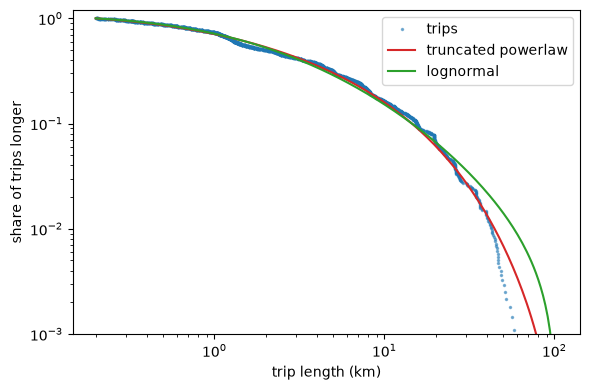

In [8]:
x = np.sort(lengths[lengths >= 0.2])
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(x, 1 - np.arange(len(x)) / len(x), ".", ms=3, alpha=0.5, label="trips")
grid = np.geomspace(0.2, xmax, 200)
for name, color in (("truncated_powerlaw", "tab:red"), ("lognormal", "tab:green")):
    f = fit_distance_distribution(lengths, name, xmin=0.2, xmax=xmax, n_bootstrap=0)
    ax.loglog(grid, 1 - f.cdf(grid), color=color, label=name.replace("_", " "))
ax.set_xlabel("trip length (km)")
ax.set_ylabel("share of trips longer")
ax.set_ylim(1e-3, 1.2)
ax.legend()
fig.tight_layout()
plt.show()

Both fitted curves follow the share of trips longer than a given length up to about 10 km. Above 30 km the log-normal stays too high, and the truncated power law follows the data to about 40 km; the longest trips (above 45 km) are rarer than either curve. The longest tail is a handful of trips, so it carries little weight in the fit.

## Step 2: flows between places

To test the mobility itself, we count trips between places. We use H3 cells of resolution 7 (about 1.2 km on a side) and keep the 40 cells with most stops, whose number of stops is their relevance (the size of the place). `trajectory_to_od` on the stops pairs consecutive stops of a person, so one row of the flow table is the number of trips from one cell to another. A `Locations` catalogue holds the cell centres and relevance, which is what the gravity model needs.

In [9]:
def busiest_cells(frame, n=40):
    """The n cells with most stops, with their number of stops as relevance."""
    counted = fastmob.latlng_to_h3(frame, resolution=7).groupby("h3_cell").size()
    return counted.rename("relevance").nlargest(n).rename_axis("tile_id")


def cell_flows(frame, cells):
    """Trips between the given cells, for the given stops, with their catalogue."""
    trips = fastmob.trajectory_to_od(frame, resolution=7).rename(columns={"count": "flow"})
    trips = trips[
        trips["origin"].isin(cells.index)
        & trips["destination"].isin(cells.index)
        & (trips["origin"] != trips["destination"])
    ].reset_index(drop=True)
    centres = fastmob.h3_to_latlng(pd.DataFrame({"h3_cell": cells.index})).rename(
        columns={"h3_cell": "tile_id", "center_lat": "lat", "center_lng": "lng"}
    )
    table = (
        centres.join(cells, on="tile_id")
        .join(trips.groupby("origin")["flow"].sum().rename("tot_outflow"), on="tile_id")
        .fillna({"tot_outflow": 0})
    )
    catalogue = Locations.from_tessellation(table, tile_id_col="tile_id", lat_col="lat", lng_col="lng")
    return FlowDataFrame(trips, locations=catalogue, tile_id="tile_id"), catalogue


people_all = np.sort(stays["uid"].unique())
cells = busiest_cells(stays)
observed, catalogue = cell_flows(stays, cells)
table = observed.to_pandas()
print(f"{len(table)} pairs of cells with trips out of {40 * 39}; {int(table['flow'].sum())} trips; largest flow {int(table['flow'].max())}")

331 pairs of cells with trips out of 1560; 1570 trips; largest flow 176


A singly constrained gravity model matches the number of trips leaving each cell and fits how they spread among destinations, `flow ∝ relevance(destination)^a * distance^gamma`. `Gravity.fit` adds the pairs of cells without trips as zeros, gives robust standard errors and a confidence interval for `gamma`, the distance-decay parameter.

In [10]:
model = Gravity(gravity_type="singly constrained")
model.fit(observed)
print(model.fit_statistics())
model.fit_summary().to_pandas().round(3)

{'n_observations': 1560, 'log_likelihood': -1971.2258359236778, 'deviance': 3054.841933895, 'pseudo_r_squared': 0.6374740635954954, 'dispersion': 5.189883995618827, 'robust_errors': True, 'cov_type': 'HC0'}


,parameter,estimate,std_error,ci_low,ci_high,p_value
0,destination_exp,0.746,0.085,0.580,0.911,0.0
1,distance_coefficient,-1.378,0.148,-1.667,-1.089,0.0


Of the 1,560 pairs of the 40 cells, 331 have trips; the other 1,229 enter the fit as zeros. The distance coefficient is -1.38 with a 95% interval of -1.67 to -1.09: the flow between two cells falls as roughly the 1.4th power of their distance, and an exponent of 1 or of 2 would both be hard to defend at this interval. The destination exponent is 0.75 (0.58 to 0.91). The dispersion is 5.2, well above 1, so the Poisson standard errors would be too small and the robust ones, which are reported, are the ones to use. The pseudo R-squared of 0.64 is mostly the size of the origins and does not show that the distance law holds; the interval of the coefficient does. The relevance is the number of stops at the destination, which are made by the same people as the trips, so the destination exponent is partly circular; the distance coefficient is much less affected. The coefficient describes the distances between the centres of 1.2 km cells.

In [11]:
rng = np.random.default_rng(0)
by_user = {u: g for u, g in stays.groupby("uid")}
coefficients = []
for _ in range(100):  # resample people, keeping the cells and their relevance fixed
    drawn = rng.choice(people_all, size=len(people_all))
    sample = pd.concat([by_user[u].assign(uid=f"{u}-{i}") for i, u in enumerate(drawn)])
    flows, _ = cell_flows(sample, cells)
    again = Gravity(gravity_type="singly constrained")
    again.fit(flows)
    coefficients.append(again.deterrence_func_args[0])
low, high = np.quantile(coefficients, [0.025, 0.975])
print(f"resampling people: distance coefficient {np.mean(coefficients):.2f}, standard deviation {np.std(coefficients):.2f}, 95% interval {low:.2f} to {high:.2f}")

exponential = Gravity(gravity_type="singly constrained", deterrence_func_type="exponential")
exponential.fit(observed)
print(f"log-likelihood: power-law deterrence {model.fit_statistics()['log_likelihood']:.0f}, exponential deterrence {exponential.fit_statistics()['log_likelihood']:.0f} (same number of parameters)")

resampling people: distance coefficient -1.36, standard deviation 0.16, 95% interval -1.69 to -1.11
log-likelihood: power-law deterrence -1971, exponential deterrence -2024 (same number of parameters)


The interval above treats the trips as independent. Resampling the 30 people (100 times, with the cells and relevance fixed) gives a standard deviation of 0.16 and an interval of -1.69 to -1.11, almost the same as the robust interval (-1.67 to -1.09), so the clustering of trips within people does not change the conclusion for the distance coefficient. The power-law deterrence also fits better than the exponential one: the log-likelihoods are -1,971 and -2,024 for the same number of parameters.

## Step 3: does the model predict flows it has not seen?

The check above fits and describes the same trips. For a test of the model, we split the people in two halves. The cells and their relevance are chosen from the first half, the gravity model is fitted on the first half's trips, and both models are scored on the second half's trips. The radiation model has no parameter to fit and uses the same catalogue, so it is the baseline. `compare_flow_models` scores every model on all the pairs of the cells, so the rows can be compared.

In [12]:
people = np.sort(stays["uid"].unique())
in_first = stays["uid"].isin(people[::2])
first, second = stays[in_first], stays[~in_first]

cells_first = busiest_cells(first)
train_flows, train_catalogue = cell_flows(first, cells_first)
test_flows, test_catalogue = cell_flows(second, cells_first)

fitted = Gravity(gravity_type="singly constrained")
fitted.fit(train_flows)
print(f"trips used to fit: {int(train_flows.to_pandas()['flow'].sum())}; trips held out: {int(test_flows.to_pandas()['flow'].sum())}")
print(fitted.fit_summary().to_pandas().round(3).to_string(index=False))

models = {
    "gravity (fitted on the first half)": fitted.generate(test_catalogue, out_format="flows"),
    "radiation": Radiation().generate(test_catalogue, out_format="flows"),
}
compare_flow_models(test_flows, models).to_pandas().set_index("model").round(3)

trips used to fit: 963; trips held out: 381
           parameter  estimate  std_error  ci_low  ci_high  p_value
     destination_exp     0.708      0.077   0.557    0.860      0.0
distance_coefficient    -1.327      0.181  -1.682   -0.971      0.0


,n_pairs,observed_flow,model_flow,cpc,cpl,r_squared,spearman,poisson_deviance,pseudo_r_squared
model,,,,,,,,,
gravity (fitted on the first half),1560,381.0,381.0,0.411,0.198,0.390,0.381,810.207,0.725
radiation,1560,381.0,346.0,0.446,0.443,0.342,0.428,5730.897,-0.949


The gravity model fitted on the first half's 963 trips gives a distance coefficient of -1.33 (-1.68 to -0.97), inside the interval of the fit on everyone, and a destination exponent of 0.71. Both models are given the number of trips that leave each cell in the second half (381 trips), so the comparison is about how those trips spread over destinations. The radiation model sends only 346 of the 381 trips (the `model_flow` column): its own normalisation loses 9%, which lowers its CPC and inflates its deviance, so its scores are a little pessimistic. On this split the scores disagree. The gravity model is far better by the Poisson deviance (810 against 5,731; the pseudo R-squared is 0.73 against -0.95, so the radiation flows are worse than a constant) and by the R-squared (0.39 against 0.34). The radiation model is slightly better by the common part of commuters (0.45 against 0.41) and the rank correlation (0.43 against 0.38). Do not read the CPL here: both models give expected flows, which are positive for every pair, so their CPL (0.20 and 0.44) reflects the number of pairs and says nothing about the model. One split of 381 trips is a weak basis for a ranking, so the next cell repeats it.

In [13]:
wins = {"R-squared": 0, "pseudo R-squared": 0, "CPC": 0, "Spearman": 0}
cpc_difference = []
for seed in range(30):
    order = np.random.default_rng(seed).permutation(people_all)
    half = stays["uid"].isin(order[: len(order) // 2])
    cells_half = busiest_cells(stays[half])
    flows_train, _ = cell_flows(stays[half], cells_half)
    flows_test, catalogue_test = cell_flows(stays[~half], cells_half)
    gravity_split = Gravity(gravity_type="singly constrained")
    gravity_split.fit(flows_train)
    scores = compare_flow_models(
        flows_test,
        {"gravity": gravity_split.generate(catalogue_test, out_format="flows"),
         "radiation": Radiation().generate(catalogue_test, out_format="flows")},
    ).to_pandas().set_index("model")
    for name, column in (("R-squared", "r_squared"), ("pseudo R-squared", "pseudo_r_squared"), ("CPC", "cpc"), ("Spearman", "spearman")):
        wins[name] += scores.loc["gravity", column] > scores.loc["radiation", column]
    cpc_difference.append(scores.loc["gravity", "cpc"] - scores.loc["radiation", "cpc"])
low, high = np.quantile(cpc_difference, [0.1, 0.9])
print("splits (of 30) in which gravity scores higher:", {k: int(v) for k, v in wins.items()})
print(f"CPC gravity minus radiation: median {np.median(cpc_difference):.2f}, 10th to 90th percentile {low:.2f} to {high:.2f}")

splits (of 30) in which gravity scores higher: {'R-squared': 29, 'pseudo R-squared': 30, 'CPC': 27, 'Spearman': 9}
CPC gravity minus radiation: median 0.06, 10th to 90th percentile 0.01 to 0.10


Over 30 random splits of the people into halves, the gravity model scores higher than radiation in 30 splits by the pseudo R-squared, in 29 by the R-squared and in 27 by the common part of commuters, but in only 9 by the rank correlation. The CPC advantage is small: a median of 0.06, with 10th to 90th percentile 0.01 to 0.10. The first split above, where radiation had the higher CPC, was one of the unlucky ones. The honest summary is that the fitted gravity model predicts the size of flows better than the parameter-free radiation model, while radiation orders the pairs about as well.

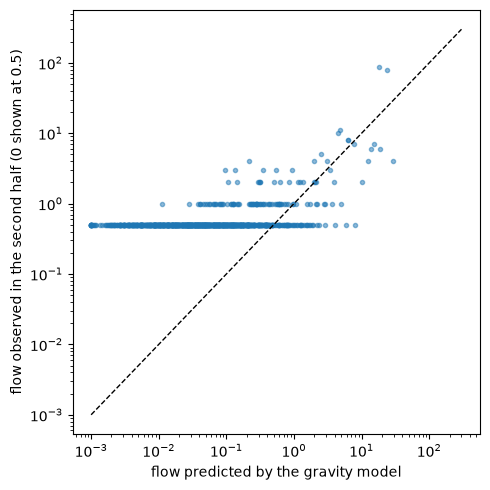

In [14]:
predicted = models["gravity (fitted on the first half)"].to_pandas()
held = test_flows.to_pandas().rename(columns={"flow": "observed"}).merge(
    predicted.rename(columns={"flow": "predicted"}), on=["origin", "destination"], how="outer"
).fillna(0)
fig, ax = plt.subplots(figsize=(5, 5))
ax.loglog(held["predicted"].clip(lower=1e-3), held["observed"].clip(lower=0.5), ".", alpha=0.5)
ax.plot([1e-3, 300], [1e-3, 300], "k--", lw=1)
ax.set_xlabel("flow predicted by the gravity model")
ax.set_ylabel("flow observed in the second half (0 shown at 0.5)")
fig.tight_layout()
plt.show()

Most pairs have no observed trip (the points at 0.5) or one, and the model predicts a small flow for them; the few large flows lie close to the line, with the two largest underpredicted by a factor of 4 to 5. A model that is calibrated in size can still miss the few pairs that carry most of the trips.

## Interpretation and limits

- A distance law is a statement about a range. The trip lengths are fitted from 0.2 km to 60 km, and the family that wins on this range need not win on another; say which range you used.
- The intervals of the distance fit resample people, because the trips of one person are not independent. With 30 people they are wide, and they describe these people, not Beijing.
- GeoLife is a sample of a research project's volunteers, mostly around one university; the flows are a sample of their movement, not of the city, and the number of stops at a cell is partly a measure of where these people live and work. The relevance is not independent of the flows, so the destination exponent partly reflects circularity (see How the fits work).
- Each hold-out has a few hundred trips, so one split has a large sampling error; that is why the notebook repeats the split. A difference between two models must be large and consistent across splits and scores before you believe it.
- The sample is the first 60 trips of 30 of the 182 GeoLife users, to keep the download small; `load_geolife(users=None)` reads all of them (313 MB). The stop definition (20 minutes, 200 m) and the H3 resolution were not varied here, and a reviewer may ask for that.
- Compare the distance exponent with the literature only for flows of the same kind, zone size and range.

## What to report

The data and the filtering, the definition of a stop and a trip, the number of trips and people, the range and family of the distance distribution with its interval (and that people were resampled), the zones and their relevance, the deterrence function and constraint of the gravity model, whether zero pairs were included, the distance coefficient with its interval, the dispersion, the hold-out design and the scores of the baseline next to those of the model. The checklist in [How the fits work](fitting-methods.md) is the complete list.

## Next steps

- How the estimators work and what to report: [How the fits work](fitting-methods.md).
- Check flows against a reference table: [Validate against census flows](validate-against-census-flows.md).
- Compare the fitted law with other data: [Compare to mobility laws](compare-to-mobility-laws.md).

## Related API

[`stay_locations`](../reference/preprocessing.md#fastmob.preprocessing.stay_locations) ·
[`jump_lengths`](../reference/measures/individual.md#fastmob.measures.individual.jump_lengths) ·
[`fit_distance_distribution`](../reference/fitting.md#fastmob.measures.fitting.distance_distribution.fit_distance_distribution) ·
[`compare_distance_distributions`](../reference/fitting.md#fastmob.measures.fitting.distance_distribution.compare_distance_distributions) ·
[`likelihood_ratio_test`](../reference/fitting.md#fastmob.measures.fitting.distribution_tests.likelihood_ratio_test) ·
[`Gravity.fit`](../reference/models.md#fastmob.models.gravity.Gravity.fit) ·
[`compare_flow_models`](../reference/measures/evaluation.md#fastmob.measures.evaluation.compare_flow_models)